In [62]:
import os.path

import pandas as pd
from glob import glob
import re
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import json
import torch
import numpy as np
from bbox_annotation import Annotation, annotation_from_json
from sklearn.model_selection import train_test_split
import cv2

import matplotlib.pyplot as plt
from tool import crop_rgb

Image.MAX_IMAGE_PIXELS = None

In [63]:
%store -r data_df

In [64]:
data_df

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
0,60811405120000_1inch tvd mudlog,dataset/images/60811405120000_1inch tvd mudlog...,1535,15029,"[236, 1205, 316, 15029]","[953, 1205, 1000, 15029]","[12, 596, 1525, 1003]"
1,Mudlog-Trail Mtn1Palisades,dataset/images/Mudlog-Trail Mtn1Palisades.tif,1650,62325,"[391, 1424, 414, 62325]","[335, 1424, 391, 62325]","[75, 691, 673, 1215]"
2,0000000009_d-582_0000020435-0001_log05_chromat...,dataset/images/0000000009_d-582_0000020435-000...,4864,13051,"[1285, 4381, 1376, 12182]","[1364, 4381, 1612, 12182]","[1937, 1513, 3029, 2655]"
3,60812401020000_xom_ocs-g_20351_ju103_st00bp00_...,dataset/images/60812401020000_xom_ocs-g_20351_...,1700,209000,"[355, 1576, 426, 208873]","[1198, 1576, 1255, 208873]","[79, 600, 1615, 1005]"
4,60818400650000_at0574_4_neptune_1inch_tvdmudlo...,dataset/images/60818400650000_at0574_4_neptune...,2307,36050,"[450, 2699, 508, 36050]","[1763, 2699, 1856, 36050]","[3, 1154, 2305, 1732]"
5,Rio_Lavaca_1748_Unit_1_241_MUD,dataset/images/Rio_Lavaca_1748_Unit_1_241_MUD.tif,1700,195800,"[280, 6861, 321, 194865]","[661, 6861, 731, 194865]","[34, 3299, 1667, 3644]"
6,60817411420000_mc_540_#1_st00_bp00_masterlog_3...,dataset/images/60817411420000_mc_540_#1_st00_b...,1538,212600,"[236, 1542, 317, 211547]","[1085, 1542, 1150, 211547]","[2, 890, 1532, 1219]"
7,60811406050000_608114060500_g31765 001 st00 bp...,dataset/images/60811406050000_608114060500_g31...,1680,238000,"[278, 1628, 343, 233912]","[1167, 1628, 1230, 233912]","[2, 600, 1538, 1021]"
8,Callaway 3-33 mudlog to TD.PDF,dataset/images/Callaway 3-33 mudlog to TD.PDF.tif,1275,56100,"[555, 5096, 615, 56024]","[250, 5096, 310, 56024]","[26, 2081, 1248, 2381]"
9,60811405800000_608114058000_g16786_001_00_00_m...,dataset/images/60811405800000_608114058000_g16...,1534,2600,"[275, 1576, 355, 2575]","[1165, 1576, 1228, 2575]","[2, 599, 1532, 1002]"


In [65]:
example_row = data_df[data_df["Name"]=="0000000009_d-582_0000020435-0001_log06_fe_5in_md"].iloc[0]

In [66]:
colbounds = example_row["Interpreted Lithology Column"]

In [67]:
column = crop_rgb(Image.open(example_row["Image"]), colbounds)

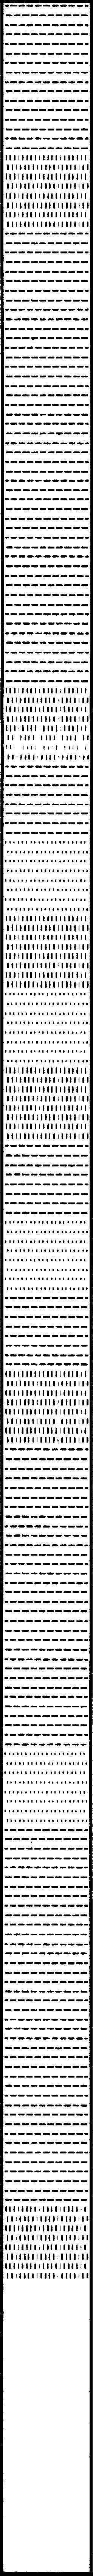

In [68]:
column

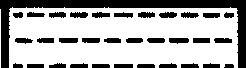

mean size 74.3 px


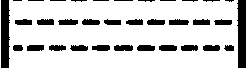

mean size 63.8 px


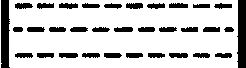

mean size 75.7 px


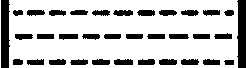

mean size 83.7 px


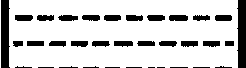

mean size 63.0 px


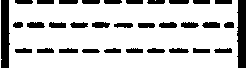

mean size 74.6 px


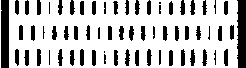

mean size 47.2 px


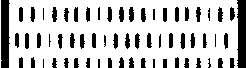

mean size 43.1 px


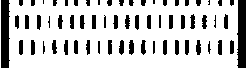

mean size 38.1 px


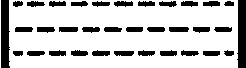

mean size 77.3 px


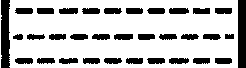

mean size 92.4 px


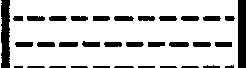

mean size 64.3 px


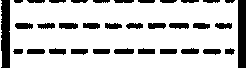

mean size 70.1 px


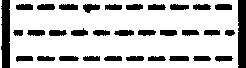

mean size 86.8 px


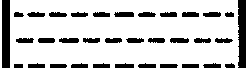

mean size 70.4 px


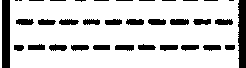

mean size 59.8 px


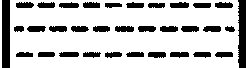

mean size 86.6 px


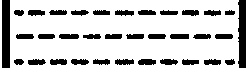

mean size 78.3 px


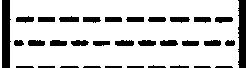

mean size 69.2 px


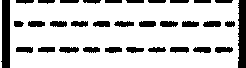

mean size 74.7 px


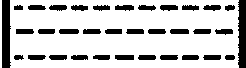

mean size 78.5 px


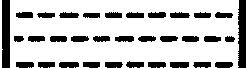

mean size 90.9 px


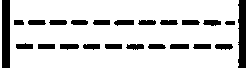

mean size 81.5 px


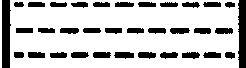

mean size 84.0 px


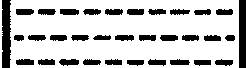

mean size 88.8 px


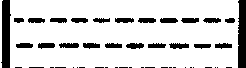

mean size 37.0 px


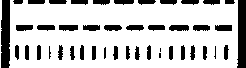

mean size 60.5 px


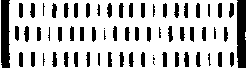

mean size 45.2 px


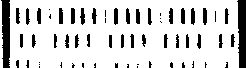

mean size 28.5 px


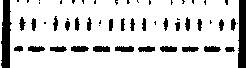

mean size 31.8 px


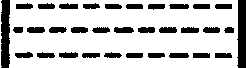

mean size 85.2 px


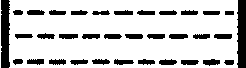

mean size 72.2 px


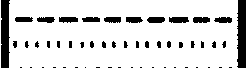

mean size 27.7 px


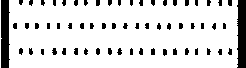

mean size 20.7 px


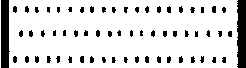

mean size 20.7 px


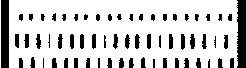

mean size 35.2 px


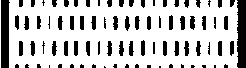

mean size 33.0 px


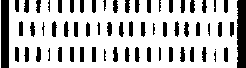

mean size 47.4 px


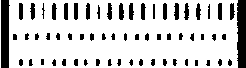

mean size 33.8 px


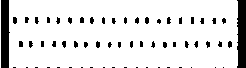

mean size 14.1 px


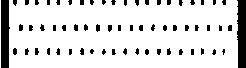

mean size 19.0 px


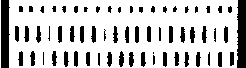

mean size 39.1 px


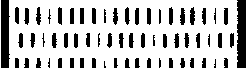

mean size 45.6 px


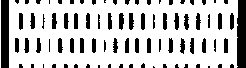

mean size 32.6 px


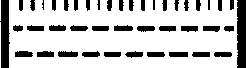

mean size 61.7 px


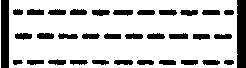

mean size 79.7 px


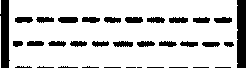

mean size 59.9 px


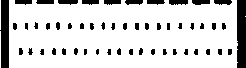

mean size 32.3 px


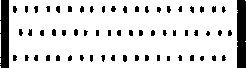

mean size 20.4 px


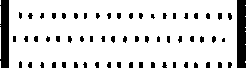

mean size 20.4 px


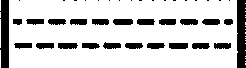

mean size 51.6 px


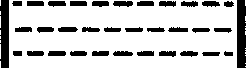

mean size 75.1 px


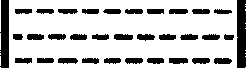

mean size 84.5 px


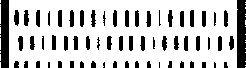

mean size 42.3 px


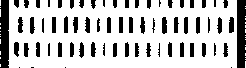

mean size 41.9 px


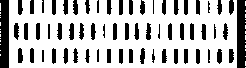

mean size 52.3 px


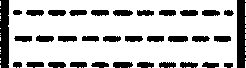

mean size 86.0 px


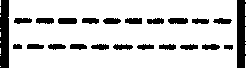

mean size 82.0 px


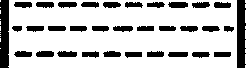

mean size 86.3 px


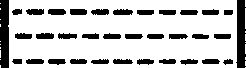

mean size 79.5 px


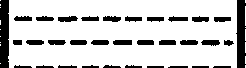

mean size 64.0 px


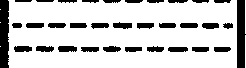

mean size 69.3 px


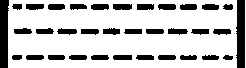

mean size 84.4 px


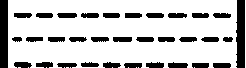

mean size 79.7 px


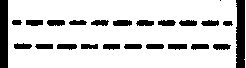

mean size 80.9 px


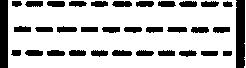

mean size 86.6 px


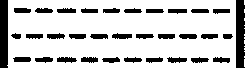

mean size 74.2 px


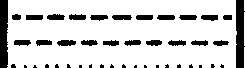

mean size 44.9 px


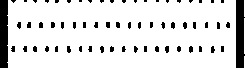

mean size 16.1 px


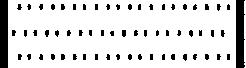

mean size 19.1 px


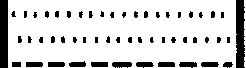

mean size 32.9 px


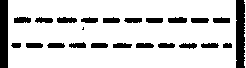

mean size 75.8 px


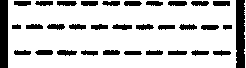

mean size 74.4 px


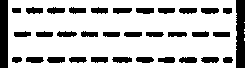

mean size 84.2 px


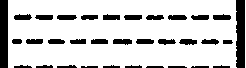

mean size 64.8 px


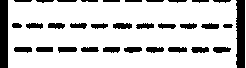

mean size 64.9 px


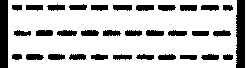

mean size 84.2 px


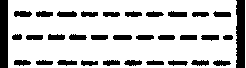

mean size 79.7 px


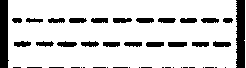

mean size 39.6 px


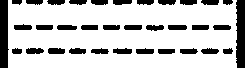

mean size 78.4 px


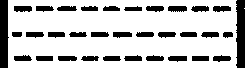

mean size 83.2 px


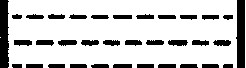

mean size 70.8 px


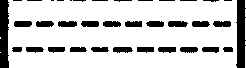

mean size 59.4 px


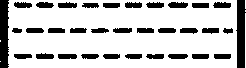

mean size 81.2 px


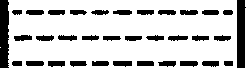

mean size 75.8 px


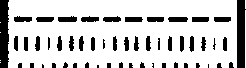

mean size 43.5 px


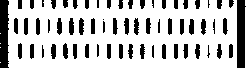

mean size 45.2 px


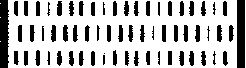

mean size 52.0 px


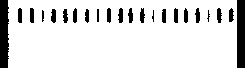

mean size 48.0 px


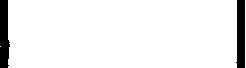

mean size 556.0 px


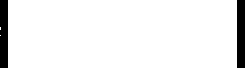

mean size 542.0 px


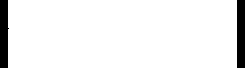

mean size 544.5 px


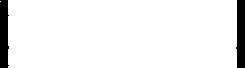

mean size 547.0 px


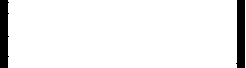

mean size 546.5 px


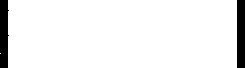

mean size 544.5 px


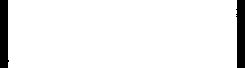

mean size 546.5 px


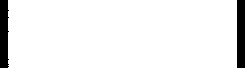

mean size 547.0 px


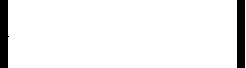

mean size 544.5 px


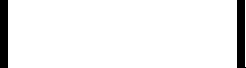

mean size 544.5 px


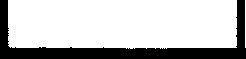

mean size 3487.0 px


In [69]:

NUM_STRIPS = 100
STRIP_HEIGHT = int(np.ceil(column.size[1] / NUM_STRIPS))   # rounded up so the strips cover the whole column
BLACK_CUTOFF = 40 * 3            
MAX_STDS = 2                     # ignore values more than this many standard deviations from the mean
WHITE = (255, 255, 255)
NEIGHBOURS = [(1, 0), (-1, 0), (0, 1), (0, -1)]  

column_width, column_height = column.size

for strip_top in range(0, column_height, STRIP_HEIGHT):
    strip_bottom = min(strip_top + STRIP_HEIGHT, column_height)
    strip = column.crop((0, strip_top, column_width, strip_bottom))
    display(strip)


    strip_rgb = strip.convert("RGB")
    width, height = strip_rgb.size
    pixels = strip_rgb.load()            # pixels[x, y] -> (r, g, b)
    island_sizes = []

    for y in range(height):
        for x in range(width):
            if sum(pixels[x, y]) >= BLACK_CUTOFF:
                continue      


            pixels[x, y] = WHITE
            to_visit = [(x, y)]
            island_size = 0

            while to_visit:
                px, py = to_visit.pop()
                island_size += 1

                for dx, dy in NEIGHBOURS:
                    nx, ny = px + dx, py + dy
                    inside_strip = 0 <= nx < width and 0 <= ny < height
                    if inside_strip and sum(pixels[nx, ny]) < BLACK_CUTOFF:
                        pixels[nx, ny] = WHITE
                        to_visit.append((nx, ny))

            island_sizes.append(island_size)

    if island_sizes:
        sizes = np.array(island_sizes)
        normal_sizes = sizes[abs(sizes - sizes.mean()) <= MAX_STDS * sizes.std()]
        mean_size = normal_sizes.mean()
    else:
        mean_size = 0

    print(f"mean size {mean_size:.1f} px")

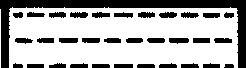

mean change in x 16.8 px, mean change in y 5.2 px


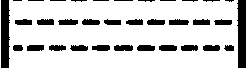

mean change in x 16.9 px, mean change in y 4.4 px


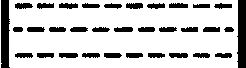

mean change in x 17.8 px, mean change in y 5.2 px


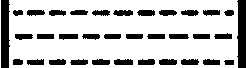

mean change in x 16.9 px, mean change in y 5.8 px


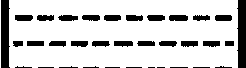

mean change in x 16.4 px, mean change in y 4.3 px


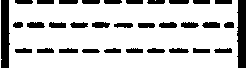

mean change in x 17.9 px, mean change in y 4.9 px


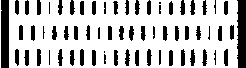

mean change in x 4.0 px, mean change in y 14.4 px


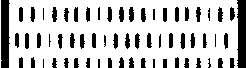

mean change in x 4.2 px, mean change in y 12.8 px


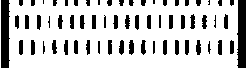

mean change in x 3.9 px, mean change in y 11.2 px


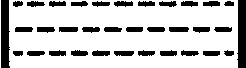

mean change in x 16.8 px, mean change in y 5.6 px


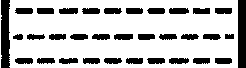

mean change in x 17.9 px, mean change in y 6.0 px


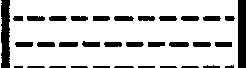

mean change in x 17.3 px, mean change in y 4.1 px


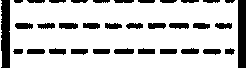

mean change in x 16.9 px, mean change in y 4.9 px


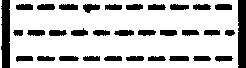

mean change in x 17.8 px, mean change in y 5.9 px


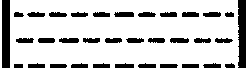

mean change in x 17.2 px, mean change in y 4.9 px


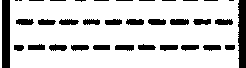

mean change in x 16.0 px, mean change in y 4.2 px


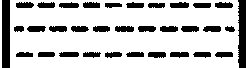

mean change in x 18.0 px, mean change in y 5.8 px


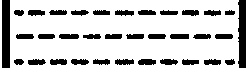

mean change in x 16.8 px, mean change in y 5.5 px


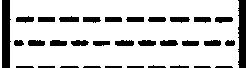

mean change in x 17.8 px, mean change in y 4.6 px


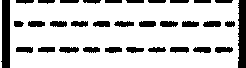

mean change in x 17.8 px, mean change in y 5.1 px


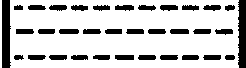

mean change in x 17.1 px, mean change in y 5.3 px


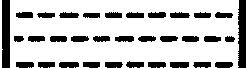

mean change in x 17.9 px, mean change in y 6.0 px


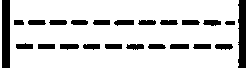

mean change in x 17.1 px, mean change in y 5.3 px


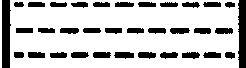

mean change in x 16.8 px, mean change in y 5.8 px


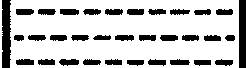

mean change in x 17.9 px, mean change in y 6.1 px


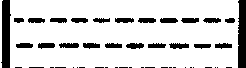

mean change in x 10.5 px, mean change in y 3.0 px


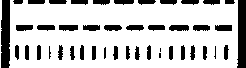

mean change in x 10.3 px, mean change in y 9.3 px


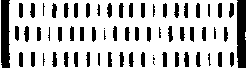

mean change in x 3.8 px, mean change in y 13.5 px


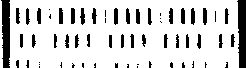

mean change in x 2.9 px, mean change in y 10.0 px


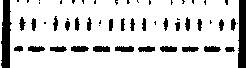

mean change in x 3.7 px, mean change in y 6.7 px


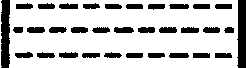

mean change in x 17.8 px, mean change in y 5.6 px


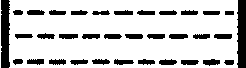

mean change in x 17.1 px, mean change in y 5.3 px


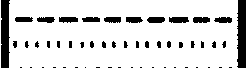

mean change in x 5.7 px, mean change in y 4.3 px


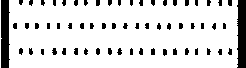

mean change in x 3.9 px, mean change in y 6.3 px


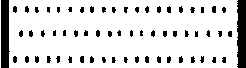

mean change in x 3.9 px, mean change in y 6.5 px


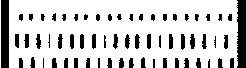

mean change in x 4.1 px, mean change in y 10.5 px


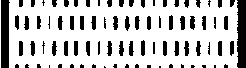

mean change in x 4.0 px, mean change in y 9.8 px


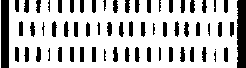

mean change in x 4.0 px, mean change in y 13.8 px


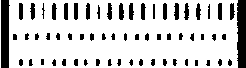

mean change in x 4.0 px, mean change in y 10.1 px


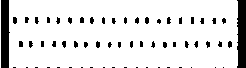

mean change in x 3.3 px, mean change in y 4.7 px


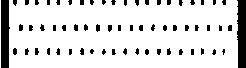

mean change in x 3.8 px, mean change in y 6.0 px


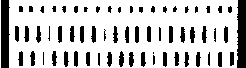

mean change in x 4.0 px, mean change in y 11.8 px


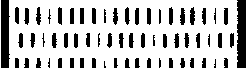

mean change in x 4.0 px, mean change in y 13.7 px


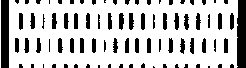

mean change in x 3.9 px, mean change in y 9.8 px


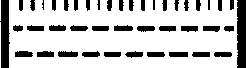

mean change in x 10.7 px, mean change in y 8.2 px


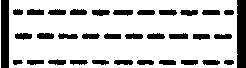

mean change in x 16.8 px, mean change in y 5.7 px


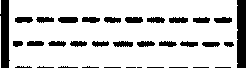

mean change in x 16.8 px, mean change in y 4.3 px


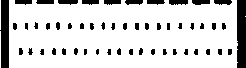

mean change in x 5.0 px, mean change in y 6.3 px


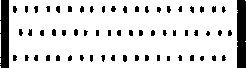

mean change in x 3.9 px, mean change in y 6.3 px


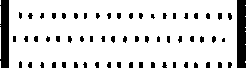

mean change in x 3.9 px, mean change in y 6.2 px


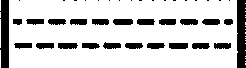

mean change in x 10.2 px, mean change in y 3.8 px


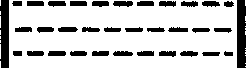

mean change in x 17.3 px, mean change in y 5.3 px


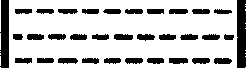

mean change in x 17.8 px, mean change in y 5.7 px


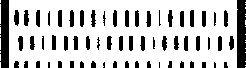

mean change in x 3.9 px, mean change in y 12.4 px


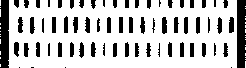

mean change in x 4.0 px, mean change in y 12.1 px


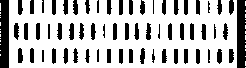

mean change in x 4.1 px, mean change in y 15.2 px


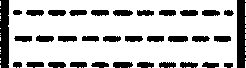

mean change in x 17.7 px, mean change in y 6.0 px


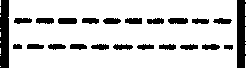

mean change in x 17.9 px, mean change in y 5.9 px


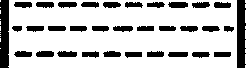

mean change in x 18.0 px, mean change in y 5.9 px


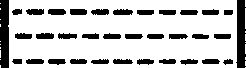

mean change in x 16.8 px, mean change in y 5.5 px


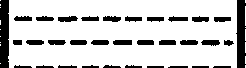

mean change in x 17.9 px, mean change in y 4.5 px


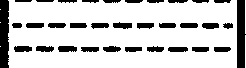

mean change in x 17.8 px, mean change in y 4.6 px


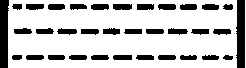

mean change in x 16.9 px, mean change in y 5.7 px


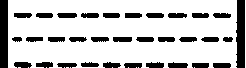

mean change in x 18.0 px, mean change in y 5.2 px


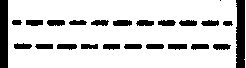

mean change in x 16.5 px, mean change in y 5.5 px


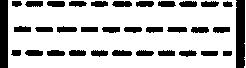

mean change in x 17.2 px, mean change in y 6.0 px


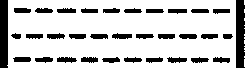

mean change in x 17.9 px, mean change in y 5.3 px


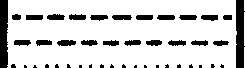

mean change in x 10.2 px, mean change in y 4.7 px


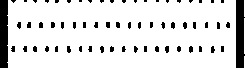

mean change in x 3.6 px, mean change in y 5.2 px


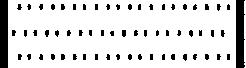

mean change in x 3.7 px, mean change in y 6.2 px


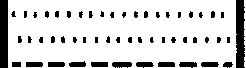

mean change in x 5.6 px, mean change in y 6.2 px


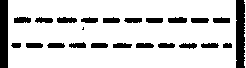

mean change in x 16.2 px, mean change in y 5.3 px


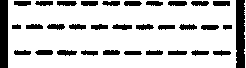

mean change in x 17.9 px, mean change in y 5.3 px


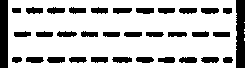

mean change in x 17.3 px, mean change in y 5.9 px


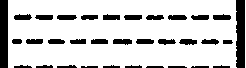

mean change in x 17.8 px, mean change in y 4.4 px


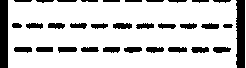

mean change in x 17.8 px, mean change in y 4.7 px


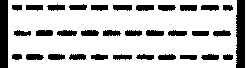

mean change in x 16.8 px, mean change in y 6.0 px


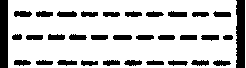

mean change in x 17.8 px, mean change in y 5.6 px


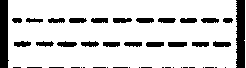

mean change in x 11.2 px, mean change in y 3.1 px


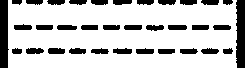

mean change in x 16.8 px, mean change in y 5.4 px


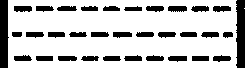

mean change in x 18.0 px, mean change in y 5.6 px


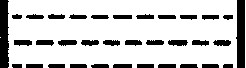

mean change in x 16.8 px, mean change in y 4.8 px


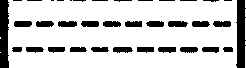

mean change in x 15.6 px, mean change in y 4.1 px


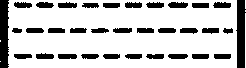

mean change in x 17.8 px, mean change in y 5.4 px


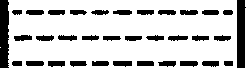

mean change in x 17.0 px, mean change in y 5.4 px


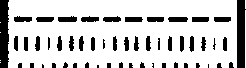

mean change in x 6.3 px, mean change in y 8.8 px


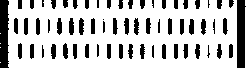

mean change in x 4.1 px, mean change in y 12.9 px


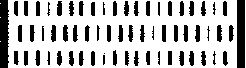

mean change in x 4.2 px, mean change in y 15.0 px


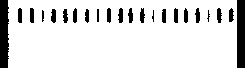

mean change in x 4.0 px, mean change in y 14.2 px


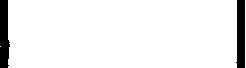

mean change in x 9.5 px, mean change in y 68.0 px


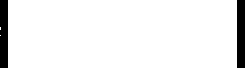

mean change in x 8.0 px, mean change in y 68.0 px


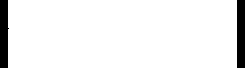

mean change in x 8.5 px, mean change in y 68.0 px


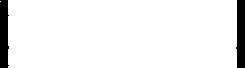

mean change in x 9.0 px, mean change in y 68.0 px


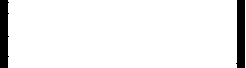

mean change in x 9.0 px, mean change in y 68.0 px


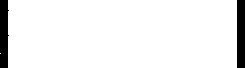

mean change in x 8.5 px, mean change in y 68.0 px


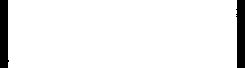

mean change in x 9.0 px, mean change in y 68.0 px


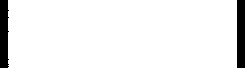

mean change in x 8.5 px, mean change in y 68.0 px


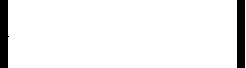

mean change in x 8.5 px, mean change in y 68.0 px


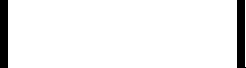

mean change in x 8.5 px, mean change in y 68.0 px


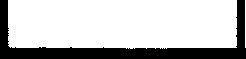

mean change in x 246.0 px, mean change in y 59.0 px


In [70]:
for strip_top in range(0, column_height, STRIP_HEIGHT):
    strip_bottom = min(strip_top + STRIP_HEIGHT, column_height)
    strip = column.crop((0, strip_top, column_width, strip_bottom))
    display(strip)

    strip_rgb = strip.convert("RGB")
    width, height = strip_rgb.size
    pixels = strip_rgb.load()
    x_changes = []
    y_changes = []

    for y in range(height):
        for x in range(width):
            if sum(pixels[x, y]) >= BLACK_CUTOFF:
                continue

            pixels[x, y] = WHITE
            to_visit = [(x, y)]
            min_x, max_x = x, x
            min_y, max_y = y, y

            while to_visit:
                px, py = to_visit.pop()
                min_x = min(min_x, px)
                max_x = max(max_x, px)
                min_y = min(min_y, py)
                max_y = max(max_y, py)

                for dx, dy in NEIGHBOURS:
                    nx, ny = px + dx, py + dy
                    inside_strip = 0 <= nx < width and 0 <= ny < height
                    if inside_strip and sum(pixels[nx, ny]) < BLACK_CUTOFF:
                        pixels[nx, ny] = WHITE
                        to_visit.append((nx, ny))

            x_changes.append(max_x - min_x + 1)
            y_changes.append(max_y - min_y + 1)

    if x_changes:
        xs = np.array(x_changes)
        ys = np.array(y_changes)
        normal_xs = xs[abs(xs - xs.mean()) <= MAX_STDS * xs.std()]
        normal_ys = ys[abs(ys - ys.mean()) <= MAX_STDS * ys.std()]
        mean_x_change = normal_xs.mean()
        mean_y_change = normal_ys.mean()
    else:
        mean_x_change = 0
        mean_y_change = 0

    print(f"mean change in x {mean_x_change:.1f} px, mean change in y {mean_y_change:.1f} px")

In [71]:
example_row["Interpreted Lithology Column"]

[2991, 4404, 3237, 11195]

## Sliding window

In [ ]:
WINDOW_HEIGHT = 100      # window height in pixels (about 5 ft on a 5-inch log)
WINDOW_STEPS = 4         # the window moves down a quarter of its height each step

# Each row's background colour: the median colour of that row's pixels that aren't black
# (the median ignores thin coloured symbols). Read from column before the islands get painted white.
column_array = np.array(column).astype(np.float32)
not_black = column_array.sum(axis=2) >= BLACK_CUTOFF
column_array[~not_black] = np.nan                   # leave black pixels out
column_array[~not_black.any(axis=1), 0] = 0         # rows that are entirely black stay black
row_colours = np.nanmedian(column_array, axis=1)

log_rgb = column.copy()  # a copy, so painting islands white doesn't change column
width, height = log_rgb.size
pixels = log_rgb.load()
island_sizes = []
x_changes = []
y_changes = []
centre_ys = []

# Find every island in the whole column once
for y in range(height):
    for x in range(width):
        if sum(pixels[x, y]) >= BLACK_CUTOFF:
            continue

        pixels[x, y] = WHITE
        to_visit = [(x, y)]
        island_size = 0
        min_x, max_x = x, x
        min_y, max_y = y, y

        while to_visit:
            px, py = to_visit.pop()
            island_size += 1
            min_x = min(min_x, px)
            max_x = max(max_x, px)
            min_y = min(min_y, py)
            max_y = max(max_y, py)

            for dx, dy in NEIGHBOURS:
                nx, ny = px + dx, py + dy
                inside_column = 0 <= nx < width and 0 <= ny < height
                if inside_column and sum(pixels[nx, ny]) < BLACK_CUTOFF:
                    pixels[nx, ny] = WHITE
                    to_visit.append((nx, ny))

        island_sizes.append(island_size)
        x_changes.append(max_x - min_x + 1)
        y_changes.append(max_y - min_y + 1)
        centre_ys.append((min_y + max_y) / 2)

sizes = np.array(island_sizes)
xs = np.array(x_changes)
ys = np.array(y_changes)
centre_ys = np.array(centre_ys)

# Sort the islands top to bottom so each window's islands can be found quickly
order = np.argsort(centre_ys)
sizes, xs, ys, centre_ys = sizes[order], xs[order], ys[order], centre_ys[order]

# Slide a window down the column and average the islands whose centre is inside it
window_tops = np.arange(0, max(height - WINDOW_HEIGHT, 0) + 1, WINDOW_HEIGHT / WINDOW_STEPS)
results = []

for window_top in window_tops:
    window_bottom = window_top + WINDOW_HEIGHT
    first = np.searchsorted(centre_ys, window_top)      # first island whose centre is in the window
    last = np.searchsorted(centre_ys, window_bottom)    # first island below the window
    window_sizes = sizes[first:last]
    window_xs = xs[first:last]
    window_ys = ys[first:last]

    if len(window_sizes) > 0:
        mean_size = window_sizes[abs(window_sizes - window_sizes.mean()) <= MAX_STDS * window_sizes.std()].mean()
        mean_x_change = window_xs[abs(window_xs - window_xs.mean()) <= MAX_STDS * window_xs.std()].mean()
        mean_y_change = window_ys[abs(window_ys - window_ys.mean()) <= MAX_STDS * window_ys.std()].mean()
    else:
        mean_size = 0
        mean_x_change = 0
        mean_y_change = 0

    results.append({
        "Top Y": colbounds[1] + round(window_top),          # same pixel rows as the image and example.csv
        "Bottom Y": colbounds[1] + round(window_bottom),
        "Islands": len(window_sizes),
        "Mean Size": mean_size,
        "Mean X Change": mean_x_change,
        "Mean Y Change": mean_y_change,
    })

features_df = pd.DataFrame(results)
features_df

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(15, 8), sharey=True, gridspec_kw={"width_ratios": [1, 1, 3, 3, 3]})

# The column itself, placed at its real pixel rows so it lines up with Top Y
axes[0].imshow(column, extent=[0, column.width, colbounds[3], colbounds[1]], aspect="auto")
axes[0].set_xticks([])
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Top Y (px)")

# Each row's background colour, from the top of the column to the bottom
axes[1].imshow(row_colours[:, None, :] / 255, extent=[0, 1, colbounds[3], colbounds[1]], aspect="auto")
axes[1].set_xticks([])
axes[1].set_xlabel("Background")

for ax, measure in zip(axes[2:], ["Mean Size", "Mean X Change", "Mean Y Change"]):
    ax.plot(features_df[measure], features_df["Top Y"])
    ax.set_xlabel(f"{measure} (px)")

axes[0].set_ylim(colbounds[3], colbounds[1])   # top of the column at the top, like the image
fig.suptitle(example_row["Name"])
plt.show()

## Big changes

In [ ]:
CHANGE_THRESHOLD = 0.4   # a jump bigger than this fraction of a graph's usual range counts as a big change
WOBBLE_FACTOR = 5        # ...but only if it is this many times bigger than the graph's usual wobble
COLOUR_CHANGE = 40       # a row this far from the current band's colour starts a new band (white to black is 441)
MIN_BAND_ROWS = 30       # ...but only if the new colour holds over the next this-many rows
BAND_SHARE = 0.8         # ...in at least this share of them (allows for thin stripes, text and symbols)
measures = ["Mean Size", "Mean X Change", "Mean Y Change"]

# Compare each window with the next window that doesn't overlap it.
# A change_score above 1 means a big change in the black marks.
change_score = np.zeros(len(features_df))

for measure in measures:
    values = features_df[measure].to_numpy()
    low, high = np.percentile(values, [1, 99])
    if high == low:
        continue

    values = np.clip(values, low, high)          # stop one huge spike from setting the scale
    jump = abs(values[WINDOW_STEPS:] - values[:-WINDOW_STEPS])
    usual_wobble = np.median(jump)
    score = jump / (high - low) / CHANGE_THRESHOLD
    score[jump <= WOBBLE_FACTOR * usual_wobble] = 0
    change_score[:-WINDOW_STEPS] = np.maximum(change_score[:-WINDOW_STEPS], score)

# Each run of big changes is one change; put the line where the change is biggest
shape_change_ys = []
i = 0

while i < len(change_score):
    if change_score[i] > 1:
        run_end = i
        while run_end + 1 < len(change_score) and change_score[run_end + 1] > 1:
            run_end += 1

        biggest = i + np.argmax(change_score[i:run_end + 1])
        shape_change_ys.append(int(features_df["Bottom Y"].iloc[biggest]))   # where the two windows meet
        i = run_end + 1
    else:
        i += 1

# Background colour changes, row by row: a new colour band starts at a row whose colour
# is far from the current band's colour, as long as most of the next MIN_BAND_ROWS rows keep the new colour
colour_change_ys = []
band_colour = row_colours[0]
y = 1

while y < len(row_colours):
    if np.linalg.norm(row_colours[y] - band_colour) > COLOUR_CHANGE:
        next_rows = row_colours[y:y + MIN_BAND_ROWS]
        share_matching = np.mean(np.linalg.norm(next_rows - row_colours[y], axis=1) <= COLOUR_CHANGE)
        if len(next_rows) == MIN_BAND_ROWS and share_matching >= BAND_SHARE:
            colour_change_ys.append(colbounds[1] + y)
            band_colour = row_colours[y]
            y += MIN_BAND_ROWS
            continue
    y += 1

# Colour lines are exact to the row, so skip a black-mark line that is right next to one
change_ys = list(colour_change_ys)
for shape_y in shape_change_ys:
    if all(abs(shape_y - colour_y) > WINDOW_HEIGHT / 2 for colour_y in colour_change_ys):
        change_ys.append(shape_y)
change_ys.sort()

print(f"{len(change_ys)} big changes at y ({len(colour_change_ys)} from colour):", change_ys)

fig, axes = plt.subplots(1, 5, figsize=(15, 8), sharey=True, gridspec_kw={"width_ratios": [1, 1, 3, 3, 3]})

# The column itself, placed at its real pixel rows so it lines up with Top Y
axes[0].imshow(column, extent=[0, column.width, colbounds[3], colbounds[1]], aspect="auto")
axes[0].set_xticks([])
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Top Y (px)")

# Each row's background colour, from the top of the column to the bottom
axes[1].imshow(row_colours[:, None, :] / 255, extent=[0, 1, colbounds[3], colbounds[1]], aspect="auto")
axes[1].set_xticks([])
axes[1].set_xlabel("Background")

for ax, measure in zip(axes[2:], ["Mean Size", "Mean X Change", "Mean Y Change"]):
    ax.plot(features_df[measure], features_df["Top Y"])
    ax.set_xlabel(f"{measure} (px)")

for ax in axes:
    for change_y in change_ys:
        ax.axhline(change_y, color="red", linewidth=0.8)

axes[0].set_ylim(colbounds[3], colbounds[1])   # top of the column at the top, like the image
fig.suptitle(f"{example_row['Name']}: {len(change_ys)} big changes")
plt.show()

## All images

In [ ]:
# Sliding-window means and row colours for every image (takes a few minutes)
all_results = []
all_row_colours = {}     # each image's background colour, one per row
column_previews = {}     # a shrunk copy of each column, for plotting

for image_number, (_, row) in enumerate(data_df.iterrows()):
    print(f"{image_number + 1}/{len(data_df)} {row['Name']}")

    column_box = row["Interpreted Lithology Column"]
    log_rgb = crop_rgb(Image.open(row["Image"]), column_box)
    width, height = log_rgb.size
    column_previews[row["Name"]] = log_rgb.resize((width, min(height, 4000)))

    # Each row's background colour: the median colour of its pixels that aren't black,
    # read before the islands get painted white
    log_array = np.array(log_rgb).astype(np.float32)
    log_not_black = log_array.sum(axis=2) >= BLACK_CUTOFF
    log_array[~log_not_black] = np.nan                   # leave black pixels out
    log_array[~log_not_black.any(axis=1), 0] = 0         # rows that are entirely black stay black
    all_row_colours[row["Name"]] = np.nanmedian(log_array, axis=1)

    pixels = log_rgb.load()
    island_sizes = []
    x_changes = []
    y_changes = []
    centre_ys = []

    # Find every island in the whole column once
    for y in range(height):
        for x in range(width):
            if sum(pixels[x, y]) >= BLACK_CUTOFF:
                continue

            pixels[x, y] = WHITE
            to_visit = [(x, y)]
            island_size = 0
            min_x, max_x = x, x
            min_y, max_y = y, y

            while to_visit:
                px, py = to_visit.pop()
                island_size += 1
                min_x = min(min_x, px)
                max_x = max(max_x, px)
                min_y = min(min_y, py)
                max_y = max(max_y, py)

                for dx, dy in NEIGHBOURS:
                    nx, ny = px + dx, py + dy
                    inside_column = 0 <= nx < width and 0 <= ny < height
                    if inside_column and sum(pixels[nx, ny]) < BLACK_CUTOFF:
                        pixels[nx, ny] = WHITE
                        to_visit.append((nx, ny))

            island_sizes.append(island_size)
            x_changes.append(max_x - min_x + 1)
            y_changes.append(max_y - min_y + 1)
            centre_ys.append((min_y + max_y) / 2)

    sizes = np.array(island_sizes)
    xs = np.array(x_changes)
    ys = np.array(y_changes)
    centre_ys = np.array(centre_ys)

    # Sort the islands top to bottom so each window's islands can be found quickly
    order = np.argsort(centre_ys)
    sizes, xs, ys, centre_ys = sizes[order], xs[order], ys[order], centre_ys[order]

    # Slide a window down the column and average the islands whose centre is inside it
    window_tops = np.arange(0, max(height - WINDOW_HEIGHT, 0) + 1, WINDOW_HEIGHT / WINDOW_STEPS)

    for window_top in window_tops:
        window_bottom = window_top + WINDOW_HEIGHT
        first = np.searchsorted(centre_ys, window_top)      # first island whose centre is in the window
        last = np.searchsorted(centre_ys, window_bottom)    # first island below the window
        window_sizes = sizes[first:last]
        window_xs = xs[first:last]
        window_ys = ys[first:last]

        if len(window_sizes) > 0:
            mean_size = window_sizes[abs(window_sizes - window_sizes.mean()) <= MAX_STDS * window_sizes.std()].mean()
            mean_x_change = window_xs[abs(window_xs - window_xs.mean()) <= MAX_STDS * window_xs.std()].mean()
            mean_y_change = window_ys[abs(window_ys - window_ys.mean()) <= MAX_STDS * window_ys.std()].mean()
        else:
            mean_size = 0
            mean_x_change = 0
            mean_y_change = 0

        all_results.append({
            "Name": row["Name"],
            "Top Y": column_box[1] + round(window_top),
            "Bottom Y": column_box[1] + round(window_bottom),
            "Islands": len(window_sizes),
            "Mean Size": mean_size,
            "Mean X Change": mean_x_change,
            "Mean Y Change": mean_y_change,
        })

all_features_df = pd.DataFrame(all_results)
all_features_df

In [ ]:
# Find the big changes in each image and draw them as red lines
LARGE_IMAGE = 20000      # images taller than this (px) also get a close-up of their top
CLOSE_UP_HEIGHT = 5000   # how many px the close-up shows

all_change_ys = {}

for _, row in data_df.iterrows():
    image_features = all_features_df[all_features_df["Name"] == row["Name"]]
    image_row_colours = all_row_colours[row["Name"]]
    column_box = row["Interpreted Lithology Column"]

    # Compare each window with the next window that doesn't overlap it.
    # A change_score above 1 means a big change in the black marks.
    change_score = np.zeros(len(image_features))

    for measure in measures:
        values = image_features[measure].to_numpy()
        low, high = np.percentile(values, [1, 99])
        if high == low:
            continue

        values = np.clip(values, low, high)          # stop one huge spike from setting the scale
        jump = abs(values[WINDOW_STEPS:] - values[:-WINDOW_STEPS])
        usual_wobble = np.median(jump)
        score = jump / (high - low) / CHANGE_THRESHOLD
        score[jump <= WOBBLE_FACTOR * usual_wobble] = 0
        change_score[:-WINDOW_STEPS] = np.maximum(change_score[:-WINDOW_STEPS], score)

    # Each run of big changes is one change; put the line where the change is biggest
    shape_change_ys = []
    i = 0

    while i < len(change_score):
        if change_score[i] > 1:
            run_end = i
            while run_end + 1 < len(change_score) and change_score[run_end + 1] > 1:
                run_end += 1

            biggest = i + np.argmax(change_score[i:run_end + 1])
            shape_change_ys.append(int(image_features["Bottom Y"].iloc[biggest]))   # where the two windows meet
            i = run_end + 1
        else:
            i += 1

    # Background colour changes, row by row: a new colour band starts at a row whose colour
    # is far from the current band's colour, as long as most of the next MIN_BAND_ROWS rows keep the new colour
    colour_change_ys = []
    band_colour = image_row_colours[0]
    y = 1

    while y < len(image_row_colours):
        if np.linalg.norm(image_row_colours[y] - band_colour) > COLOUR_CHANGE:
            next_rows = image_row_colours[y:y + MIN_BAND_ROWS]
            share_matching = np.mean(np.linalg.norm(next_rows - image_row_colours[y], axis=1) <= COLOUR_CHANGE)
            if len(next_rows) == MIN_BAND_ROWS and share_matching >= BAND_SHARE:
                colour_change_ys.append(column_box[1] + y)
                band_colour = image_row_colours[y]
                y += MIN_BAND_ROWS
                continue
        y += 1

    # Colour lines are exact to the row, so skip a black-mark line that is right next to one
    change_ys = list(colour_change_ys)
    for shape_y in shape_change_ys:
        if all(abs(shape_y - colour_y) > WINDOW_HEIGHT / 2 for colour_y in colour_change_ys):
            change_ys.append(shape_y)
    change_ys.sort()

    all_change_ys[row["Name"]] = change_ys

    # Always chart the whole column; large images also get a full-resolution close-up of their top
    charts = [("whole column", column_box[1], column_box[3], column_previews[row["Name"]])]

    if column_box[3] - column_box[1] > LARGE_IMAGE:
        close_up_bottom = column_box[1] + CLOSE_UP_HEIGHT
        close_up = crop_rgb(Image.open(row["Image"]), (column_box[0], column_box[1], column_box[2], close_up_bottom))
        charts.append((f"top {CLOSE_UP_HEIGHT} px", column_box[1], close_up_bottom, close_up))

    for chart_name, chart_top, chart_bottom, chart_image in charts:
        chart_features = image_features[(image_features["Top Y"] >= chart_top) & (image_features["Top Y"] < chart_bottom)]
        chart_row_colours = image_row_colours[chart_top - column_box[1]:chart_bottom - column_box[1]]
        chart_changes = [y for y in change_ys if chart_top <= y <= chart_bottom]

        fig, axes = plt.subplots(1, 5, figsize=(15, 8), sharey=True, gridspec_kw={"width_ratios": [1, 1, 3, 3, 3]})

        axes[0].imshow(chart_image, extent=[0, 1, chart_bottom, chart_top], aspect="auto")
        axes[0].set_xticks([])
        axes[0].set_xlabel("Column")
        axes[0].set_ylabel("Top Y (px)")

        axes[1].imshow(chart_row_colours[:, None, :] / 255, extent=[0, 1, chart_bottom, chart_top], aspect="auto")
        axes[1].set_xticks([])
        axes[1].set_xlabel("Background")

        for ax, measure in zip(axes[2:], measures):
            ax.plot(chart_features[measure], chart_features["Top Y"])
            ax.set_xlabel(f"{measure} (px)")

        for ax in axes:
            for change_y in chart_changes:
                ax.axhline(change_y, color="red", linewidth=0.8)

        axes[0].set_ylim(chart_bottom, chart_top)   # top of the column at the top, like the image
        fig.suptitle(f"{row['Name']} ({chart_name}): {len(chart_changes)} big changes")
        plt.show()